# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?

Para poder obtener la respuesta impusliva de cualquier sistema LTI se debe inyectar en la entrada un impulso unitario (Delta de Dirac) y obtener la salida del sistema a partir de esa señal de entrada.

- ¿Qué representa en el caso del filtro de promedio móvil?

Para el filtro de promedio movil la respuesta al impulso se tiene un escalon del ancho de la ventana (N_WINDOW) y atenuado por un factor inverso al ancho de la ventana (1 / N_WINDOW). Esto debido a que se busca promediar los valores.


In [39]:
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt

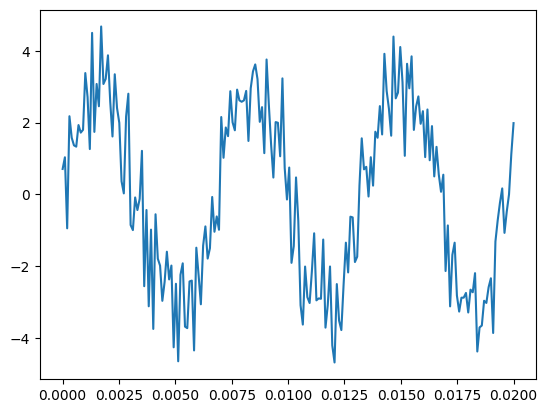

In [40]:
########### Parámetros Iniciales ###########
Fs = 10000   # Sampling Freq 10KHz
N = 200      # Samples number
t = np.linspace(0,N/Fs,num=N) # Crea una variable de tiempo desde 0, con intervalos de 1/Fs

f1 = 150   # 100Hz
A1 = 3

signal = A1 * np.sin(2*np.pi*f1*t)

noise = np.random.normal(0,1,len(signal))
sig_noise = signal + noise
plt.plot(t,sig_noise)

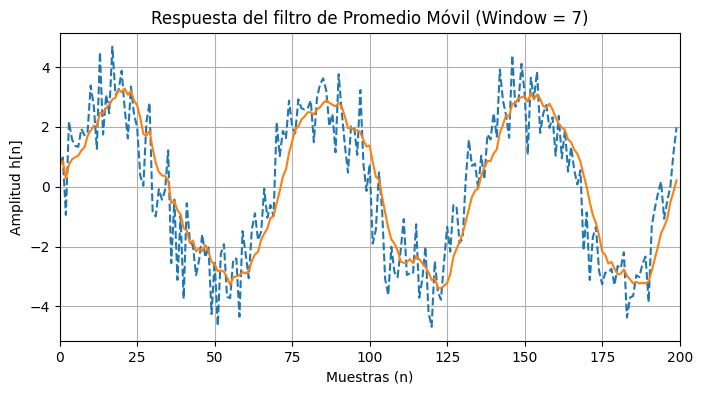

In [76]:
def algoritmo_promedio_movil(y_in, n_window):
    y = np.zeros(y_in.size)

    # Si la salida necesita valores al inicio
    for i in range(y_in.size):
        if i < n_window:
            y[i] = np.sum(y_in[0 : i+1]) / (i + 1)
        else:
            y[i] = np.sum(y_in[i - n_window + 1 : i+1]) / n_window
    # Esperar a los n valores de la ventana para empezar a promediar
    # for i in range(0, y_in.size - n_window):
    #     y[i + n_window] = np.sum(y_in[i:i+n_window]) / n_window

    return y

def plot_promedio_movil(y1, y2, n_window):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(np.arange(0, y1.size), y1, label="Original", linestyle='--')
    ax.plot(np.arange(0, y2.size), y2, label="Filtrada", linestyle="-")
    ax.set_title(f"Respuesta del filtro de Promedio Móvil (Window = {n_window})")
    ax.set_xlabel("Muestras (n)")
    ax.set_xlim(0, y1.size)
    ax.set_ylabel("Amplitud h[n]")
    ax.grid(True)
    return fig

N_WINDOW = 7
avg = algoritmo_promedio_movil(sig_noise, N_WINDOW)
plot_avg = plot_promedio_movil(sig_noise, avg, N_WINDOW)
plot_avg.show()

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

Las formas de onda se modifican principalmente en sus flancos, volviendolos una pendiente y no una conmutacion pronunciada. Ademas, se observa como el promediado de muestras en la señal triangular termina atenuando la amplitud de la señal.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?

Como resultado en la señal, el filtro de promedio movil se comporta como un filtro pasa bajos (LPF).


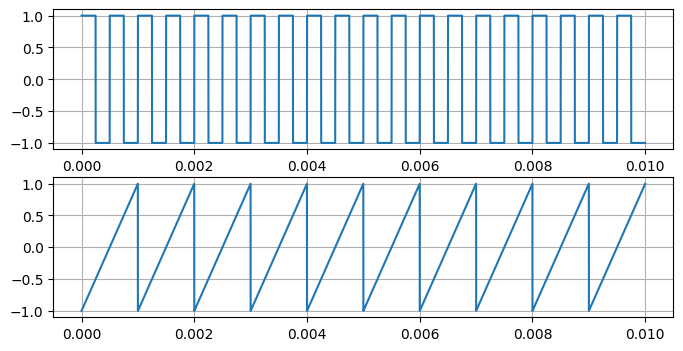

In [77]:
Ts = 10e-3
f1 = 2e3
f2 = 1e3

t = np.linspace(0, Ts, Fs, endpoint=False)

y1 = sig.square(2 * np.pi * f1 * t)
y2 = sig.sawtooth(2 * np.pi * f2 * t)

def make_subplots_2_signals(t, y1, y2):
    fig, ax = plt.subplots(2, 1, figsize=(8, 4))
    ax[0].plot(t, y1)
    ax[1].plot(t,y2)
    ax[0].grid()
    ax[1].grid()
    return fig

fig = make_subplots_2_signals(t, y1, y2)
fig.show()

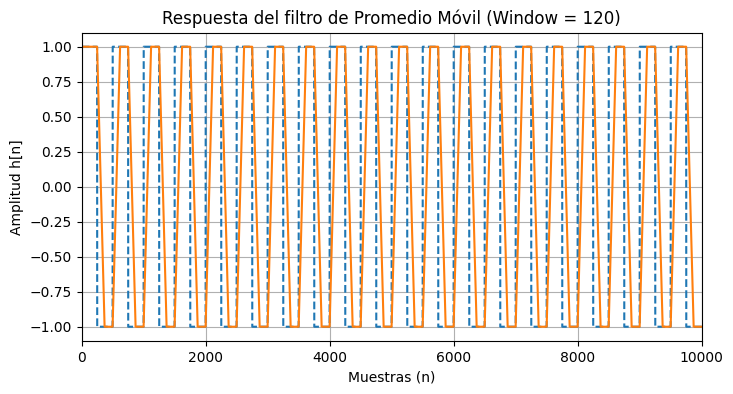

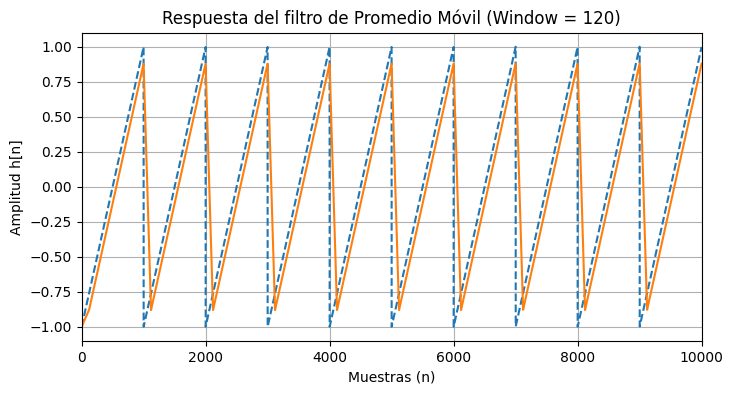

In [86]:
N_WINDOW_SIGNAL = 120
avg = algoritmo_promedio_movil(y1, N_WINDOW_SIGNAL)
fig = plot_promedio_movil(y1, avg, N_WINDOW_SIGNAL)
fig.show()
avg = algoritmo_promedio_movil(y2, N_WINDOW_SIGNAL)
fig = plot_promedio_movil(y2, avg, N_WINDOW_SIGNAL)
fig.show()

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando la funcion fijo() de ejemplo.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficar todas las señales calculadas

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?

    Entre las implementaciones se puede observar que la libreria numpy es 3 ordenes de magnitud mas rapida. En el grafico comparativo se observa que todas las señales tienen la misma forma y no hay una gran distorsion en particular.

    - ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

    Al comparar el punto fijo vs flotante se observa que a bajas muestras la convolucion fija es ligeramente mas rapido pero a medida que se tienen N mayores se emparejan los valores y la resolucion flotante es ligeramente menor.
    Es importante destacar que el Google Colab cuenta con hardware para realizar operaciones de punto flotante, por ende su tiempo de computacion es bajo, pero en microcontroladores sin unidad de punto flotante el tiempo se dispararia. Rindiendo mejor las convoluciones de punto fijo.

In [130]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

fs = 100000      # Frecuencia de muestreo
N = 500        # Duración total
t = np.arange(0,N/fs,1/fs)

f1 = 250
f2 = 500

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

# Escribí tu código acá
def conv_float(x1, x2):
    y = np.zeros(x1.size + x2.size - 1)
    for i in range(x1.size):
        for j in range(x2.size):
            y[i+j] += x1[i] * x2[j]
    return y

def conv_fijo(x1, x2, frac_bits=15):
    y = np.zeros(x1.size + x2.size - 1, dtype=np.int64)
    for i in range(x1.size):
        for j in range(x2.size):
            y[i+j] += x1[i] * x2[j]
    return y / (1 << (2 * frac_bits))

def comparar_implementaciones(t):
    x1 = np.sin(2*np.pi*f1*t)
    x2 = np.sin(2*np.pi*f2*t)

    frac_bits = 15
    xf1 = fijo(x1, frac_bits).astype(np.int64)
    xf2 = fijo(x2, frac_bits).astype(np.int64)

    t_float = timeit.timeit(lambda: conv_float(x1,x2), number=20)
    t_fijo = timeit.timeit(lambda: conv_fijo(xf1, xf2, frac_bits), number=20)
    t_np = timeit.timeit(lambda: np.convolve(x1,x2), number=20)
    print(f"Tiempo Float (Python): {t_float:.5f} s")
    print(f"Tiempo Fijo (Python):  {t_fijo:.5f} s")
    print(f"Tiempo NumPy:          {t_np:.5f} s")

for n in [500, 1000, 2500]:
    print(f'Comparacion de tiempos para N = {n}')
    comparar_implementaciones(np.arange(0,n/fs,1/fs))
    print("---" * 5)
    print()

Comparacion de tiempos para N = 500
Tiempo Float (Python): 5.16476 s
Tiempo Fijo (Python):  3.06535 s
Tiempo NumPy:          0.00142 s
---------------

Comparacion de tiempos para N = 1000
Tiempo Float (Python): 12.57183 s
Tiempo Fijo (Python):  13.17676 s
Tiempo NumPy:          0.00418 s
---------------

Comparacion de tiempos para N = 2500
Tiempo Float (Python): 78.26662 s
Tiempo Fijo (Python):  81.68264 s
Tiempo NumPy:          0.02168 s
---------------



In [133]:
x1 = np.sin(2*np.pi*f1*t)
x2 = np.sin(2*np.pi*f2*t)

frac_bits = 15
xf1 = fijo(x1, frac_bits).astype(np.int64)
xf2 = fijo(x2, frac_bits).astype(np.int64)

y_float = conv_float(x1, x2)
y_fijo = conv_fijo(xf1, xf2, frac_bits)
y_np = np.convolve(x1, x2)

# Cálculo de error del punto fijo respecto al float ideal
error_absoluto = np.abs(y_float - y_fijo)
print(f"Error Máximo Punto Fijo: {np.max(error_absoluto):.5f}")
print(f"Error Medio Punto Fijo:  {np.mean(error_absoluto):.5f}")

Error Máximo Punto Fijo: 0.00050
Error Medio Punto Fijo:  0.00018


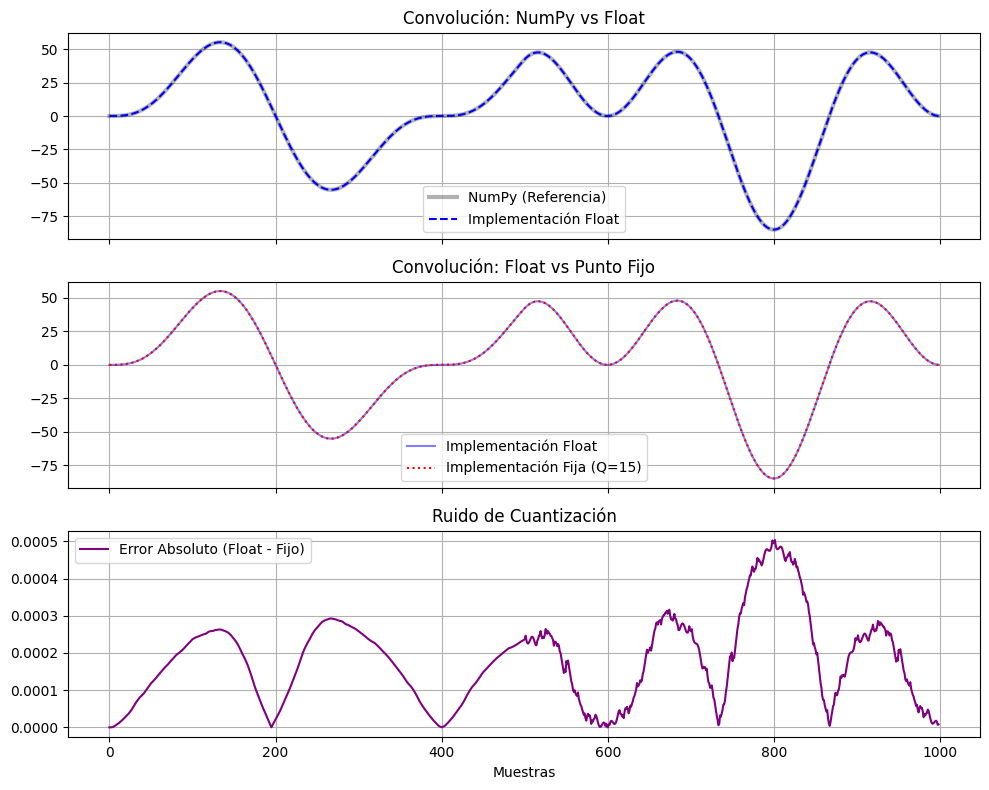

In [134]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

ax1.plot(y_np, label="NumPy (Referencia)", color='black', linewidth=3, alpha=0.3)
ax1.plot(y_float, label="Implementación Float", color='blue', linestyle='--')
ax1.set_title("Convolución: NumPy vs Float")
ax1.legend(loc=8)
ax1.grid()

ax2.plot(y_float, label="Implementación Float", color='blue', alpha=0.5)
ax2.plot(y_fijo, label=f"Implementación Fija (Q=15)", color='red', linestyle=':')
ax2.set_title("Convolución: Float vs Punto Fijo")
ax2.legend(loc=8)
ax2.grid()

ax3.plot(error_absoluto, label="Error Absoluto (Float - Fijo)", color='purple')
ax3.set_title("Ruido de Cuantización")
ax3.set_xlabel("Muestras")
ax3.legend()
ax3.grid()

plt.tight_layout()
plt.show()